In [1]:

from google.colab import drive
import pandas as pd


In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df=pd.read_csv('/Restaurant_revenue.csv')

In [6]:
df

,Number_of_Customers,Menu_Price,Marketing_Spend,Cuisine_Type,Average_Customer_Spending,Promotions,Reviews,Monthly_Revenue
0,18,39.468228,13.765230,Japanese,43.168846,1,44,343.342038
1,79,45.456115,19.251152,Japanese,33.763839,1,1,952.787741
2,68,46.842288,8.047334,American,19.794190,0,67,617.046990
3,49,30.145317,9.076554,American,39.827000,0,45,518.486532
4,48,30.811005,16.430336,Mexican,13.379236,1,77,420.898681
...,...,...,...,...,...,...,...,...
995,66,35.517470,10.920687,Japanese,10.565063,0,47,439.587122
996,57,44.249160,11.492809,Mexican,13.809344,0,99,514.043837
997,42,35.242618,5.023081,Mexican,28.127677,1,35,389.365507
998,96,23.906945,16.569564,Mexican,23.586499,0,56,701.167817


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Number_of_Customers        1000 non-null   int64  
 1   Menu_Price                 1000 non-null   float64
 2   Marketing_Spend            1000 non-null   float64
 3   Cuisine_Type               1000 non-null   object 
 4   Average_Customer_Spending  1000 non-null   float64
 5   Promotions                 1000 non-null   int64  
 6   Reviews                    1000 non-null   int64  
 7   Monthly_Revenue            1000 non-null   float64
dtypes: float64(4), int64(3), object(1)
memory usage: 62.6+ KB


In [8]:
df.isnull().sum()

,0
Number_of_Customers,0
Menu_Price,0
Marketing_Spend,0
Cuisine_Type,0
Average_Customer_Spending,0
Promotions,0
Reviews,0
Monthly_Revenue,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Number_of_Customers,1000.0,54.774000,25.993703,10.000000,32.000000,55.000000,78.000000,99.000000
Menu_Price,1000.0,30.064980,11.757590,10.020750,19.745991,29.739241,40.506733,49.976876
Marketing_Spend,1000.0,10.479211,5.487933,1.010794,5.748069,10.360532,15.365901,19.995541
Average_Customer_Spending,1000.0,29.742889,11.611045,10.025692,19.907727,29.779510,39.815185,49.976357
Promotions,1000.0,0.512000,0.500106,0.000000,0.000000,1.000000,1.000000,1.000000
Reviews,1000.0,49.414000,28.140585,0.000000,25.000000,48.000000,72.250000,99.000000
Monthly_Revenue,1000.0,535.911179,245.446425,110.257449,340.073864,495.382997,690.985293,1290.966997


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

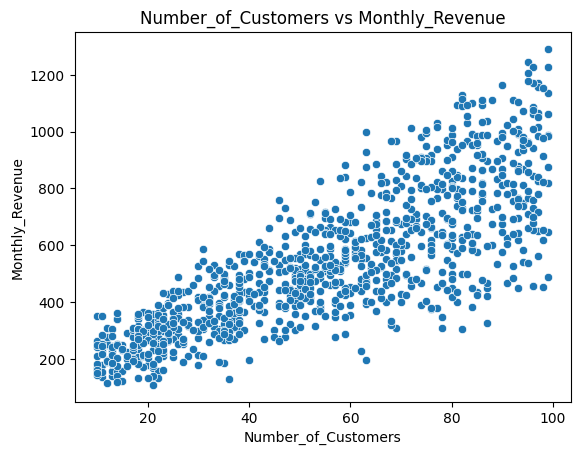

In [14]:
sns.scatterplot( data=df, x='Number_of_Customers', y='Monthly_Revenue')
plt.title('Number_of_Customers vs Monthly_Revenue')
plt.show()


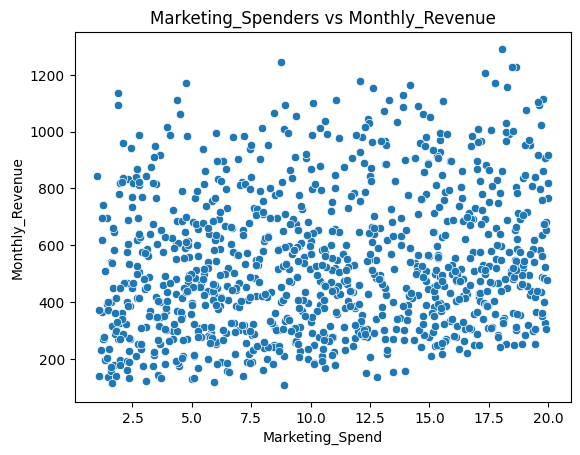

In [15]:
sns.scatterplot( data=df, x='Marketing_Spend', y='Monthly_Revenue')
plt.title('Marketing_Spenders vs Monthly_Revenue')
plt.show()

In [17]:
numeric_df= df.select_dtypes(include='number')

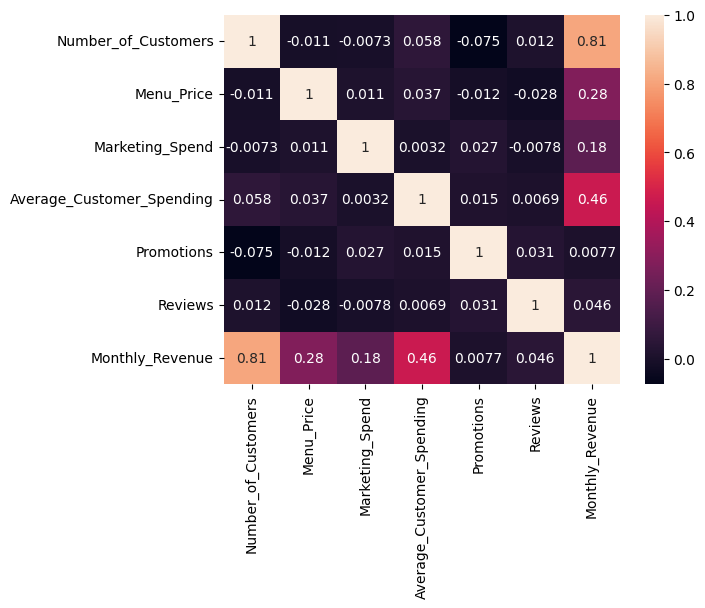

In [18]:
sns.heatmap(numeric_df.corr(), annot=True)
plt.show()

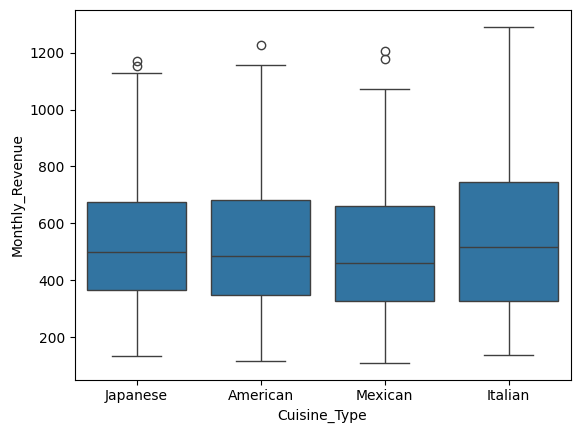

In [19]:
sns.boxplot(data=df , x='Cuisine_Type', y='Monthly_Revenue')
plt.show()

In [20]:
df.groupby('Cuisine_Type')['Monthly_Revenue'].sum().sort_values(ascending=False)

,Monthly_Revenue
Cuisine_Type,
American,139748.504008
Japanese,136608.775285
Italian,134694.077962
Mexican,124859.821633


In [40]:
df=pd.read_csv('/Restaurant_revenue.csv')

In [41]:
for i in df.columns:

    if (df[i].dtype == 'int64') | (df[i].dtype == 'float64'):

        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        outliers = df[(df[i] < lower_limit) | (df[i] > upper_limit)]

        if outliers.empty:
            print('No outliers in column', i)

        else:
            print('Outliers found in column', i)
            print(outliers)

No outliers in column Number_of_Customers
No outliers in column Menu_Price
No outliers in column Marketing_Spend
No outliers in column Average_Customer_Spending
No outliers in column Promotions
No outliers in column Reviews
Outliers found in column Monthly_Revenue
     Number_of_Customers  Menu_Price  Marketing_Spend Cuisine_Type  \
382                   95   47.415255         8.758137      Italian   
447                   96   44.053386        18.661885      Italian   
809                   99   47.820796        18.064282      Italian   
819                   99   44.085813        18.465666     American   

     Average_Customer_Spending  Promotions  Reviews  Monthly_Revenue  
382                  46.895583           0       72      1245.639619  
447                  40.261879           0       61      1226.830428  
809                  41.926732           0       71      1290.966997  
819                  43.637779           0       21      1228.359798  


In [42]:
df.dtypes

,0
Number_of_Customers,int64
Menu_Price,float64
Marketing_Spend,float64
Cuisine_Type,object
Average_Customer_Spending,float64
Promotions,int64
Reviews,int64
Monthly_Revenue,float64


In [48]:
from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()

In [49]:
df['Cuisine_Type']=le.fit_transform(df['Cuisine_Type'])

In [50]:
df.corr(numeric_only=True)['Monthly_Revenue']

,Monthly_Revenue
Number_of_Customers,0.810272
Menu_Price,0.276275
Marketing_Spend,0.181764
Cuisine_Type,-0.030802
Average_Customer_Spending,0.460295
Promotions,0.007738
Reviews,0.045932
Monthly_Revenue,1.000000


In [54]:
top_4_features= df.corr(numeric_only=True)['Monthly_Revenue'].sort_values(ascending=False)[1:5]

In [55]:
top_4_features

,Monthly_Revenue
Number_of_Customers,0.810272
Average_Customer_Spending,0.460295
Menu_Price,0.276275
Marketing_Spend,0.181764


In [58]:
x=df[top_4_features.index]
y=df['Monthly_Revenue']

In [59]:
x


,Number_of_Customers,Average_Customer_Spending,Menu_Price,Marketing_Spend
0,18,43.168846,39.468228,13.765230
1,79,33.763839,45.456115,19.251152
2,68,19.794190,46.842288,8.047334
3,49,39.827000,30.145317,9.076554
4,48,13.379236,30.811005,16.430336
...,...,...,...,...
995,66,10.565063,35.517470,10.920687
996,57,13.809344,44.249160,11.492809
997,42,28.127677,35.242618,5.023081
998,96,23.586499,23.906945,16.569564


In [60]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [62]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()

In [63]:
model.fit(x_train,y_train)

LinearRegression()

In [70]:
predict= model.predict(x_test)

In [72]:
comparision=pd.DataFrame(
    {
        'Actual':y_test,
        'Predicted':predict
    }
)

In [73]:
comparision

,Actual,Predicted
521,314.557386,417.921521
737,403.694382,457.904174
740,664.465730,700.565174
660,206.969686,106.462950
411,300.675186,261.303624
...,...,...
408,739.992813,826.946259
332,313.841455,213.634371
208,312.848436,286.423469
613,662.262699,701.323177


In [76]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [79]:
def evaluate_model(y_test, predict):
  mse = mean_squared_error(y_test, predict)

  r2 = r2_score(y_test,predict)

  print("MSE:", mse)
  print("R2 Score:", r2)


In [85]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
models={
    'Linear Regression':LinearRegression(),
    'Decision Tree':DecisionTreeRegressor(),
    'Random Forest':RandomForestRegressor(),

}
for name,model in models.items():
  print(name)
  model.fit(x_train,y_train)
  predict=model.predict(x_test)
  evaluate_model(y_test,predict)
  print('---------------------------')


Linear Regression
MSE: 4363.788083622317
R2 Score: 0.9289209506125504
---------------------------
Decision Tree
MSE: 5326.329284453906
R2 Score: 0.9132427113762921
---------------------------
Random Forest
MSE: 2063.556202364538
R2 Score: 0.966388007297574
---------------------------


In [86]:
# random forest is the best model among these 3